In [ ]:
import pandas as pd
import numpy as np


In [24]:
df1 = pd.read_csv('Conjunto_datos_BASICO_AgroCebada2026.csv')
df2 = pd.read_csv('Conjunto_datos_PRO_AgroCebada.csv')
y = pd.read_csv('ID_area_rendimiento_70_30_Reto_AgroCebada.csv')

Carga y estandarización

In [25]:
# Eliminar columnas residuales 
y = y.loc[:, ~y.columns.str.contains('^Unnamed')].copy()
df1 = df1.loc[:, ~df1.columns.str.contains('^Unnamed')].copy()
df2 = df2.loc[:, ~df2.columns.str.contains('^Unnamed')].copy()

In [26]:
df1.columns = df1.columns.str.strip()
df2.columns = df2.columns.str.strip()
y.columns = y.columns.str.strip()

In [27]:
df1['ID_POLIGONO'] = df1['ID_POLIGONO'].astype(str).str.strip()
df2['ID_POLIGONO'] = df2['ID_POLIGONO'].astype(str).str.strip()
y['ID_POLIGONO'] = y['ID_POLIGONO'].astype(str).str.strip()

# Limpieza en variables categóricas
df1['sensor'] = df1['sensor'].astype(str).str.strip()
df2['sensor'] = df2['sensor'].astype(str).str.strip()
y['CONJUNTO'] = y['CONJUNTO'].astype(str).str.strip()

In [ ]:
# Conversión estricta a formato fecha 
df1['fecha_captura'] = pd.to_datetime(df1['fecha_captura'], dayfirst=True)
df2['fecha_captura'] = pd.to_datetime(df2['fecha_captura'], dayfirst=True)

# Asegurar tipos numéricos de punto flotante en la tabla objetivo
y['AREA_HA'] = pd.to_numeric(y['AREA_HA'], errors='coerce')
y['RENDIMIENTO_T_HA'] = pd.to_numeric(y['RENDIMIENTO_T_HA'], errors='coerce')

In [29]:
# Verificación de integridad entre datasets
parcelas_y = set(y['ID_POLIGONO'].unique())
parcelas_df1 = set(df1['ID_POLIGONO'].unique())
parcelas_df2 = set(df2['ID_POLIGONO'].unique())

print("=== REPORTE DE ESTANDARIZACIÓN ===")
print(f"Total parcelas en y:   {len(parcelas_y)} (Esperadas: 197)")
print(f"Total parcelas en df1: {len(parcelas_df1)}")
print(f"Total parcelas en df2: {len(parcelas_df2)}")
print(f"¿df1 cubre todas las parcelas?: {parcelas_y.issubset(parcelas_df1)}")
print(f"¿df2 cubre todas las parcelas?: {parcelas_y.issubset(parcelas_df2)}")
print(f"Rango temporal df1: {df1['fecha_captura'].min().date()} a {df1['fecha_captura'].max().date()}")
print(f"Rango temporal df2: {df2['fecha_captura'].min().date()} a {df2['fecha_captura'].max().date()}")

=== REPORTE DE ESTANDARIZACIÓN ===
Total parcelas en y:   197 (Esperadas: 197)
Total parcelas en df1: 197
Total parcelas en df2: 197
¿df1 cubre todas las parcelas?: True
¿df2 cubre todas las parcelas?: True
Rango temporal df1: 2022-01-01 a 2025-12-31
Rango temporal df2: 2025-01-01 a 2025-12-30


Control de calidad

In [30]:
# 1. Parámetros agronómicos y de calidad
FECHA_MIN = '2025-04-01'
FECHA_MAX = '2025-10-31'
UMBRAL_NUBES = 30.0

In [31]:
def filtrar_condiciones_base(df):
    return df[
        (df['fecha_captura'] >= FECHA_MIN) & 
        (df['fecha_captura'] <= FECHA_MAX) & 
        (df['porcentaje_nubosidad'].fillna(100) <= UMBRAL_NUBES)
    ].copy()

df1_base = filtrar_condiciones_base(df1)
df2_base = filtrar_condiciones_base(df2)

In [32]:
# 3. Criterio de Faltantes Estructurales (Desacoplamiento por Sensor)
# Sentinel-2: Conservar registros multiespectrales completos
s2_qc = df1_base[
    (df1_base['sensor'] == 'Sentinel-2') & 
    (df1_base['ndvi_promedio'].notna())
].copy()

# Landsat: Conservar únicamente la serie espectro-térmica
landsat_qc = df1_base[
    (df1_base['sensor'] == 'Landsat') & 
    (df1_base['vi6t_promedio'].notna())
].copy()

# Planet (PRO): Observaciones de alta resolución válidas
planet_qc = df2_base[df2_base['ndvi_promedio'].notna()].copy()

In [33]:
s2_qc = s2_qc[(s2_qc['ndvi_promedio'] > 0.05) & (s2_qc['ndvi_promedio'] <= 1.0)]
planet_qc = planet_qc[(planet_qc['ndvi_promedio'] > 0.05) & (planet_qc['ndvi_promedio'] <= 1.0)]

# Verificación de calidad en la variable objetivo (y)
# Confirmar que los 59 nulos correspondan estrictamente al conjunto de predicción
nulos_rendimiento = y['RENDIMIENTO_T_HA'].isnull().sum()
nulos_prediccion = y[y['CONJUNTO'] == 'PREDICCION']['RENDIMIENTO_T_HA'].isnull().sum()

print("=== REPORTE DE CONTROL DE CALIDAD ===")
print(f"• Registros depurados Sentinel-2: {len(s2_qc)}")
print(f"• Registros depurados Landsat:    {len(landsat_qc)}")
print(f"• Registros depurados Planet:     {len(planet_qc)}")
print(f"• Nulos en RENDIMIENTO_T_HA:      {nulos_rendimiento} (Exactos en PREDICCION: {nulos_rendimiento == nulos_prediccion == 59})")

=== REPORTE DE CONTROL DE CALIDAD ===
• Registros depurados Sentinel-2: 6531
• Registros depurados Landsat:    3474
• Registros depurados Planet:     16148
• Nulos en RENDIMIENTO_T_HA:      59 (Exactos en PREDICCION: True)


 Análisis exploratorio 

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

In [35]:
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (14, 5)

In [36]:
df_train_y = y[y['CONJUNTO'] == 'ENTRENAMIENTO'].copy()

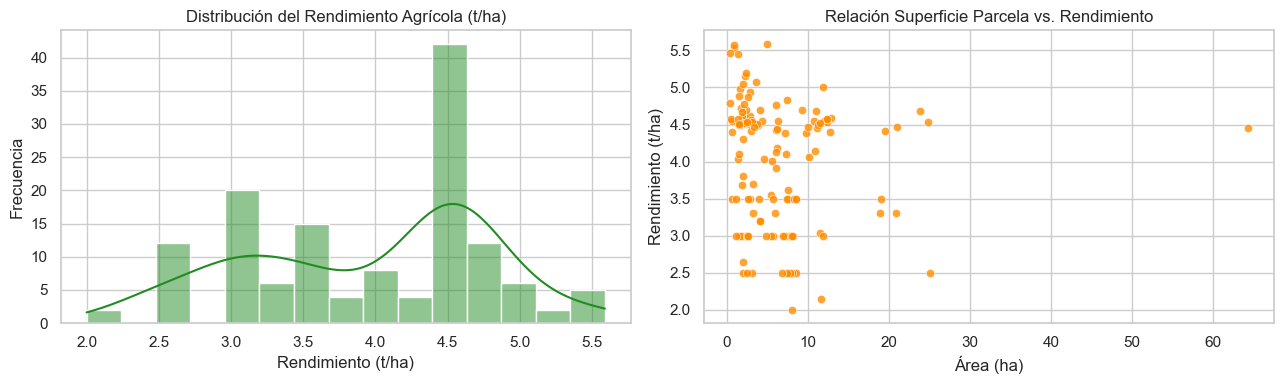

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Histograma y densidad del rendimiento
sns.histplot(df_train_y['RENDIMIENTO_T_HA'], kde=True, ax=axes[0], color='forestgreen', bins=15)
axes[0].set_title('Distribución del Rendimiento Agrícola (t/ha)')
axes[0].set_xlabel('Rendimiento (t/ha)')
axes[0].set_ylabel('Frecuencia')

# Diagrama de dispersión: Área vs. Rendimiento
sns.scatterplot(data=df_train_y, x='AREA_HA', y='RENDIMIENTO_T_HA', ax=axes[1], color='darkorange', alpha=0.8)
axes[1].set_title('Relación Superficie Parcela vs. Rendimiento')
axes[1].set_xlabel('Área (ha)')
axes[1].set_ylabel('Rendimiento (t/ha)')
plt.tight_layout()
plt.show()

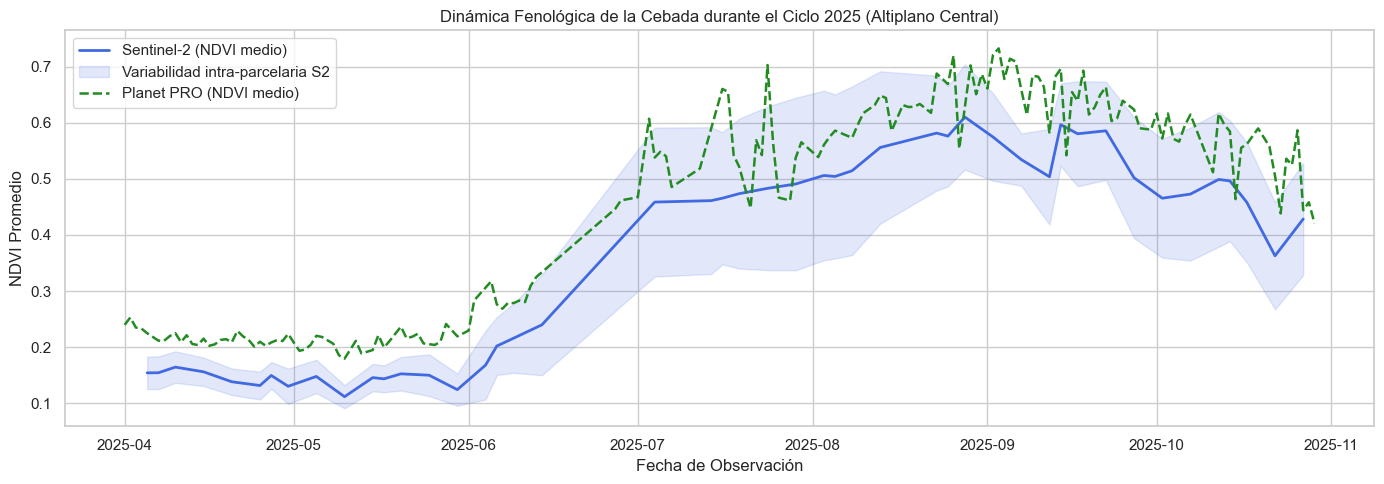

In [41]:
# 2. DESCRIPCIÓN TEMPORAL: Curva Fenológica del Ciclo 2025 (Abril - Octubre)
# Agrupación temporal por fecha de captura para observar la evolución del dosel
serie_s2 = s2_qc.groupby('fecha_captura')['ndvi_promedio'].agg(['mean', 'std']).reset_index()
serie_planet = planet_qc.groupby('fecha_captura')['ndvi_promedio'].agg(['mean', 'std']).reset_index()

plt.figure(figsize=(14, 5))
plt.plot(serie_s2['fecha_captura'], serie_s2['mean'], label='Sentinel-2 (NDVI medio)', color='royalblue', lw=2)
plt.fill_between(serie_s2['fecha_captura'], 
                 serie_s2['mean'] - serie_s2['std'], 
                 serie_s2['mean'] + serie_s2['std'], 
                 color='royalblue', alpha=0.15, label='Variabilidad intra-parcelaria S2')

plt.plot(serie_planet['fecha_captura'], serie_planet['mean'], label='Planet PRO (NDVI medio)', color='forestgreen', lw=1.8, linestyle='--')

plt.title('Dinámica Fenológica de la Cebada durante el Ciclo 2025 (Altiplano Central)')
plt.xlabel('Fecha de Observación')
plt.ylabel('NDVI Promedio')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

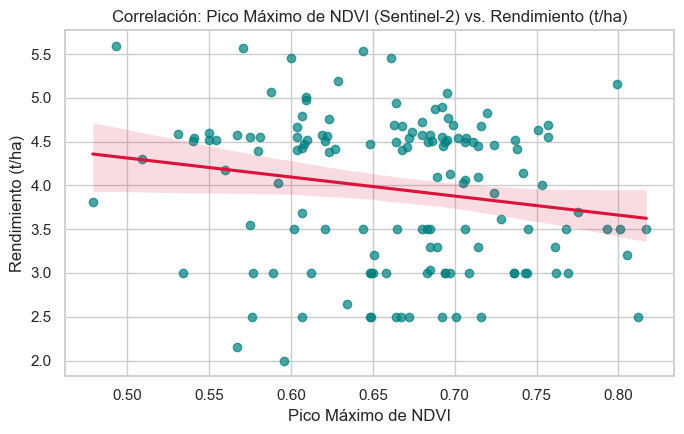

Coeficiente de correlación de Pearson (NDVI Máximo vs Rendimiento): -0.1788


In [42]:
# 3. RELACIÓN EXPLORATORIA: Vigor Máximo vs. Rendimiento Final
# Extracción rápida del pico de NDVI por parcela en entrenamiento
max_ndvi_s2 = s2_qc.groupby('ID_POLIGONO')['ndvi_promedio'].max().reset_index(name='ndvi_max_s2')
eda_merge = df_train_y.merge(max_ndvi_s2, on='ID_POLIGONO', how='inner')

plt.figure(figsize=(7, 4.5))
sns.regplot(data=eda_merge, x='ndvi_max_s2', y='RENDIMIENTO_T_HA', 
            scatter_kws={'alpha':0.7, 'color':'teal'}, line_kws={'color':'crimson'})
plt.title('Correlación: Pico Máximo de NDVI (Sentinel-2) vs. Rendimiento (t/ha)')
plt.xlabel('Pico Máximo de NDVI')
plt.ylabel('Rendimiento (t/ha)')
plt.tight_layout()
plt.show()

correlacion = eda_merge['ndvi_max_s2'].corr(eda_merge['RENDIMIENTO_T_HA'])
print(f"Coeficiente de correlación de Pearson (NDVI Máximo vs Rendimiento): {correlacion:.4f}")

In [43]:
# =======================================================
# ETAPA 6: CONSTRUCCIÓN DE VARIABLES (FEATURE ENGINEERING)
# Resultado: Variables agregadas por parcela y ciclo agrícola
# =======================================================

def construir_metricas_fenologicas(df, prefijo, variables):
    """
    Condensa la serie temporal de cada parcela en un vector estático 
    de indicadores estadístico-agronómicos del ciclo 2025.
    """
    agregaciones = {}
    for var in variables:
        agregaciones[f'{prefijo}_{var}_max'] = (var, 'max')        # Vigor fotosintético pico (etapa reproductiva)
        agregaciones[f'{prefijo}_{var}_mean'] = (var, 'mean')      # Vigor vegetativo medio estacional
        agregaciones[f'{prefijo}_{var}_integral'] = (var, 'sum')   # Integral temporal: proxy de biomasa total acumulada
        agregaciones[f'{prefijo}_{var}_std'] = (var, 'std')        # Estabilidad y tasa de maduración/senescencia
    
    return df.groupby('ID_POLIGONO').agg(**agregaciones).reset_index()

# 1. Extracción de índices según taxonomía y sensor físico
# Sentinel-2: dinámica multiespectral de vegetación, suelo y estrés hídrico
indices_s2 = ['ndvi_promedio', 'evi_promedio', 'savi_promedio', 'ndwi_promedio']
feat_s2 = construir_metricas_fenologicas(s2_qc, 's2', indices_s2)

# Planet (PRO): resolución espacial fina para dosel, vigor y estructura foliar
indices_planet = ['ndvi_promedio', 'evi_promedio', 'lai_promedio', 'msavi_promedio']
feat_planet = construir_metricas_fenologicas(planet_qc, 'planet', indices_planet)

# Landsat: comportamiento espectro-térmico de superficie
feat_landsat = construir_metricas_fenologicas(landsat_qc, 'landsat', ['vi6t_promedio'])

# 2. Consolidación de la matriz maestra a nivel parcela
# Unión con la tabla objetivo conservando las 197 geometrías
matriz_features = y.merge(feat_planet, on='ID_POLIGONO', how='left')
matriz_features = matriz_features.merge(feat_s2, on='ID_POLIGONO', how='left')
matriz_features = matriz_features.merge(feat_landsat, on='ID_POLIGONO', how='left')

# 3. Incorporación de variables derivadas
# Rango dinámico estacional en alta resolución (amplitud entre cobertura máxima e inicio)
if 'planet_ndvi_promedio_max' in matriz_features.columns and 'planet_ndvi_promedio_mean' in matriz_features.columns:
    matriz_features['planet_ndvi_amplitud'] = (
        matriz_features['planet_ndvi_promedio_max'] - matriz_features['planet_ndvi_promedio_mean']
    )

print(f"Dimensiones de la matriz final de características: {matriz_features.shape}")
print(f"Total de predictores generados: {matriz_features.shape[1] - 3} (excluyendo ID_POLIGONO, CONJUNTO y RENDIMIENTO_T_HA)")
matriz_features.head()

Dimensiones de la matriz final de características: (197, 41)
Total de predictores generados: 38 (excluyendo ID_POLIGONO, CONJUNTO y RENDIMIENTO_T_HA)


,ID_POLIGONO,AREA_HA,RENDIMIENTO_T_HA,CONJUNTO,planet_ndvi_promedio_max,planet_ndvi_promedio_mean,planet_ndvi_promedio_integral,planet_ndvi_promedio_std,planet_evi_promedio_max,planet_evi_promedio_mean,...,s2_savi_promedio_std,s2_ndwi_promedio_max,s2_ndwi_promedio_mean,s2_ndwi_promedio_integral,s2_ndwi_promedio_std,landsat_vi6t_promedio_max,landsat_vi6t_promedio_mean,landsat_vi6t_promedio_integral,landsat_vi6t_promedio_std,planet_ndvi_amplitud
0,AGC_001,7.61,3.50,ENTRENAMIENTO,0.836,0.388692,35.371,0.244846,0.693,0.254385,...,0.140973,0.444,0.086743,3.036,0.209711,-0.596,-0.624417,-7.493,0.019961,0.447308
1,AGC_002,2.31,4.63,ENTRENAMIENTO,0.835,0.443067,39.433,0.236962,0.677,0.292416,...,0.146750,0.351,0.074032,2.295,0.203832,-0.580,-0.622684,-11.831,0.024009,0.391933
2,AGC_003,18.68,NaN,PREDICCION,0.829,0.444270,27.989,0.212288,0.656,0.267905,...,0.129492,0.426,0.056813,1.818,0.222355,-0.612,-0.645154,-8.387,0.015247,0.384730
3,AGC_004,8.00,3.00,ENTRENAMIENTO,0.700,0.401227,38.919,0.179293,0.481,0.256227,...,0.102864,0.276,-0.003139,-0.113,0.156787,-0.616,-0.631000,-8.834,0.008771,0.298773
4,AGC_005,2.27,5.16,ENTRENAMIENTO,0.871,0.472750,41.602,0.242805,0.798,0.328102,...,0.159773,0.439,-0.034833,-1.045,0.257654,-0.611,-0.639125,-15.339,0.013614,0.398250


In [44]:
from sklearn.model_selection import KFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# =======================================================
# ETAPA 7: SEPARACIÓN Y VALIDACIÓN
# Resultado: Esquema de evaluación sin fuga de información
# =======================================================

# 1. Definición estricta de variables predictoras
cols_no_predictoras = ['ID_POLIGONO', 'CONJUNTO', 'RENDIMIENTO_T_HA']
predictores = [col for col in matriz_features.columns if col not in cols_no_predictoras]

# 2. Separación en conjuntos oficiales del reto
train_mask = matriz_features['CONJUNTO'] == 'ENTRENAMIENTO'
pred_mask = matriz_features['CONJUNTO'] == 'PREDICCION'

df_train = matriz_features[train_mask].copy().reset_index(drop=True)
df_test = matriz_features[pred_mask].copy().reset_index(drop=True)

X_train = df_train[predictores]
y_train = df_train['RENDIMIENTO_T_HA']

X_test = df_test[predictores]
id_test = df_test['ID_POLIGONO']

# 3. Configuración del esquema de validación cruzada (5-Fold CV)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

print("=== ESQUEMA DE PARTICIÓN Y VALIDACIÓN CONFIGURADO ===")
print(f"• Parcelas de entrenamiento supervisado: {X_train.shape[0]} (Etiqueta observada)")
print(f"• Parcelas de evaluación ciega (test):   {X_test.shape[0]} (Objetivo a predecir)")
print(f"• Número de predictores por parcela:     {len(predictores)}")
print(f"• Esquema de validación interna:         5-Fold Cross-Validation")

# 4. Demostración de aislamiento por pliegue (Prevención de Data Leakage)
# Cada pliegue entrena imputadores y transformadores exclusivamente con su fold de train
for fold, (idx_tr, idx_val) in enumerate(kf.split(X_train), start=1):
    X_tr_fold, X_val_fold = X_train.iloc[idx_tr], X_train.iloc[val_idx]
    y_tr_fold, y_val_fold = y_train.iloc[idx_tr], y_train.iloc[val_idx]
    
    # Imputación ajustada únicamente con los datos del pliegue de entrenamiento
    imputer_fold = SimpleImputer(strategy='median')
    X_tr_imputed = imputer_fold.fit_transform(X_tr_fold)
    X_val_imputed = imputer_fold.transform(X_val_fold)
    
    print(f"  Fold {fold}: Train={X_tr_imputed.shape[0]} parcelas | Validación={X_val_imputed.shape[0]} parcelas")

=== ESQUEMA DE PARTICIÓN Y VALIDACIÓN CONFIGURADO ===
• Parcelas de entrenamiento supervisado: 138 (Etiqueta observada)
• Parcelas de evaluación ciega (test):   59 (Objetivo a predecir)
• Número de predictores por parcela:     38
• Esquema de validación interna:         5-Fold Cross-Validation
  Fold 1: Train=110 parcelas | Validación=27 parcelas
  Fold 2: Train=110 parcelas | Validación=27 parcelas
  Fold 3: Train=110 parcelas | Validación=27 parcelas
  Fold 4: Train=111 parcelas | Validación=27 parcelas
  Fold 5: Train=111 parcelas | Validación=27 parcelas


Modelado predictivo

In [46]:
import numpy as np
import xgboost as xgb
from sklearn.model_selection import KFold
from sklearn.impute import SimpleImputer
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# =======================================================
# ETAPA 8: MODELADO PREDICTIVO CON XGBOOST
# Resultado: Modelos entrenados, regularizados y validados
# =======================================================

# 1. Configuración de validación cruzada (5-Fold CV)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

r2_scores, rmse_scores, mae_scores, nrmse_scores = [], [], [], []

# Almacenar importancia de variables por pliegue
importancias_folds = []

# 2. Bucle de validación cruzada con aislamiento estricto
for fold, (idx_tr, idx_val) in enumerate(kf.split(X_train), start=1):
    X_tr, X_val = X_train.iloc[idx_tr], X_train.iloc[idx_val]
    y_tr, y_val = y_train.iloc[idx_tr], y_train.iloc[idx_val]
    
    # Imputación independiente por pliegue para evitar fuga de información
    imputer = SimpleImputer(strategy='median')
    X_tr_imp = imputer.fit_transform(X_tr)
    X_val_imp = imputer.transform(X_val)
    
    # Configuración de hiperparámetros optimizada para datasets reducidos (138 parcelas)
    modelo_xgb = xgb.XGBRegressor(
        n_estimators=120,          # Número moderado de árboles para controlar sobreajuste
        max_depth=3,               # Profundidad baja para evitar memorización con N=138
        learning_rate=0.04,        # Tasa de aprendizaje suave para convergencia estable
        subsample=0.8,             # Muestreo de filas por árbol para reducir varianza
        colsample_bytree=0.8,      # Muestreo de características por árbol
        reg_alpha=0.1,             # Regularización L1 (Lasso) para penalizar pesos irrelevantes
        reg_lambda=1.0,            # Regularización L2 (Ridge) para estabilizar coeficientes
        random_state=42,
        objective='reg:squarederror'
    )
    
    modelo_xgb.fit(X_tr_imp, y_tr)
    y_pred_val = modelo_xgb.predict(X_val_imp)
    
    # Métricas de evaluación
    r2 = r2_score(y_val, y_pred_val)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred_val))
    mae = mean_absolute_error(y_val, y_pred_val)
    nrmse = (rmse / y_val.mean()) * 100
    
    r2_scores.append(r2)
    rmse_scores.append(rmse)
    mae_scores.append(mae)
    nrmse_scores.append(nrmse)
    importancias_folds.append(modelo_xgb.feature_importances_)

# 3. Reporte comparativo de desempeño frente al benchmark de la investigación
print("=== RESULTADOS DE VALIDACIÓN CRUZADA: XGBOOST (5-FOLD) ===")
print(f"• R² promedio:    {np.mean(r2_scores):.4f} (Benchmark literatura GERA: 0.83 - 0.91)")
print(f"• RMSE promedio:  {np.mean(rmse_scores):.4f} t/ha (Benchmark literatura GERA: ~0.45 - 0.65 t/ha)")
print(f"• MAE promedio:   {np.mean(mae_scores):.4f} t/ha (Benchmark literatura GERA: ~0.38 t/ha)")
print(f"• nRMSE promedio: {np.mean(nrmse_scores):.2f}% (Benchmark literatura GERA: 8.0% - 12.0%)")

# =======================================================
# 4. ENTRENAMIENTO DEFINITIVO DEL MODELO
# =======================================================
# Imputar entrenamiento completo y transferir ajuste a evaluación ciega
imputer_final = SimpleImputer(strategy='median')
X_train_final = imputer_final.fit_transform(X_train)
X_test_final = imputer_final.transform(X_test)

modelo_final_xgb = xgb.XGBRegressor(
    n_estimators=120,
    max_depth=3,
    learning_rate=0.04,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.0,
    random_state=42,
    objective='reg:squarederror'
)

modelo_final_xgb.fit(X_train_final, y_train)

# Inferencia ciega en las 59 parcelas objetivo
y_pred_test = modelo_final_xgb.predict(X_test_final)

df_resultados_xgb = pd.DataFrame({
    'ID_POLIGONO': id_test,
    'RENDIMIENTO_PREDICHO_T_HA': np.round(y_pred_test, 3)
})

print(f"\nPredicciones generadas con éxito para {len(df_resultados_xgb)} parcelas.")
df_resultados_xgb.head()

=== RESULTADOS DE VALIDACIÓN CRUZADA: XGBOOST (5-FOLD) ===
• R² promedio:    0.3316 (Benchmark literatura GERA: 0.83 - 0.91)
• RMSE promedio:  0.6679 t/ha (Benchmark literatura GERA: ~0.45 - 0.65 t/ha)
• MAE promedio:   0.5152 t/ha (Benchmark literatura GERA: ~0.38 t/ha)
• nRMSE promedio: 16.88% (Benchmark literatura GERA: 8.0% - 12.0%)

Predicciones generadas con éxito para 59 parcelas.


,ID_POLIGONO,RENDIMIENTO_PREDICHO_T_HA
0,AGC_003,3.601
1,AGC_011,4.678
2,AGC_016,4.158
3,AGC_025,3.315
4,AGC_027,2.882


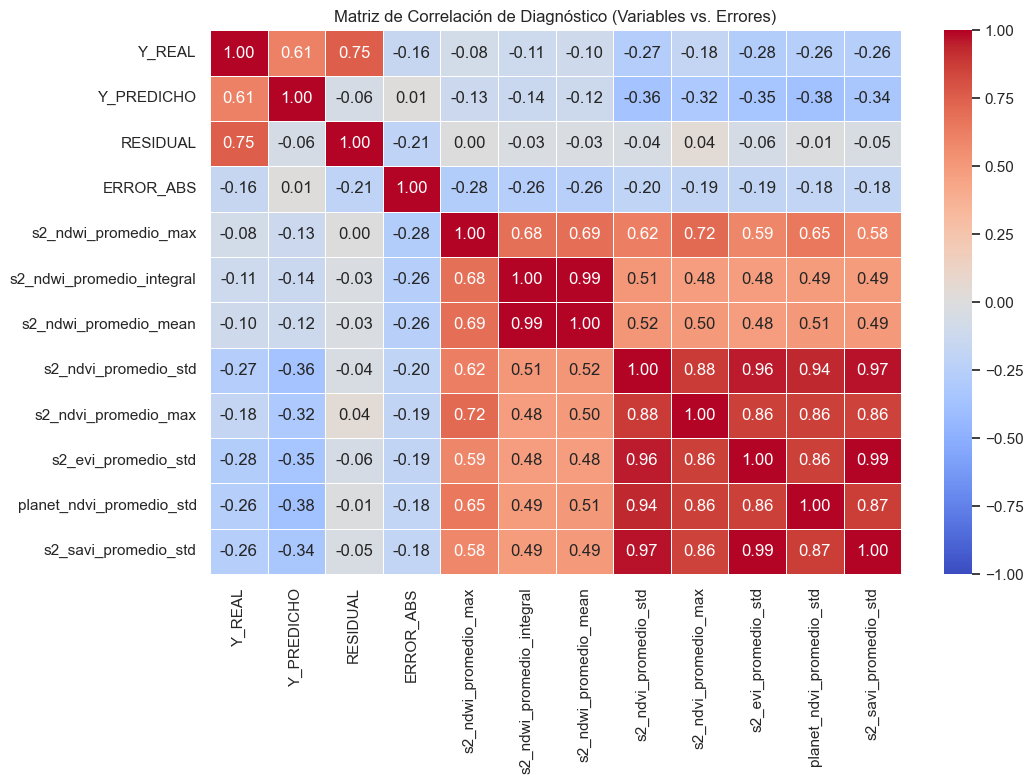

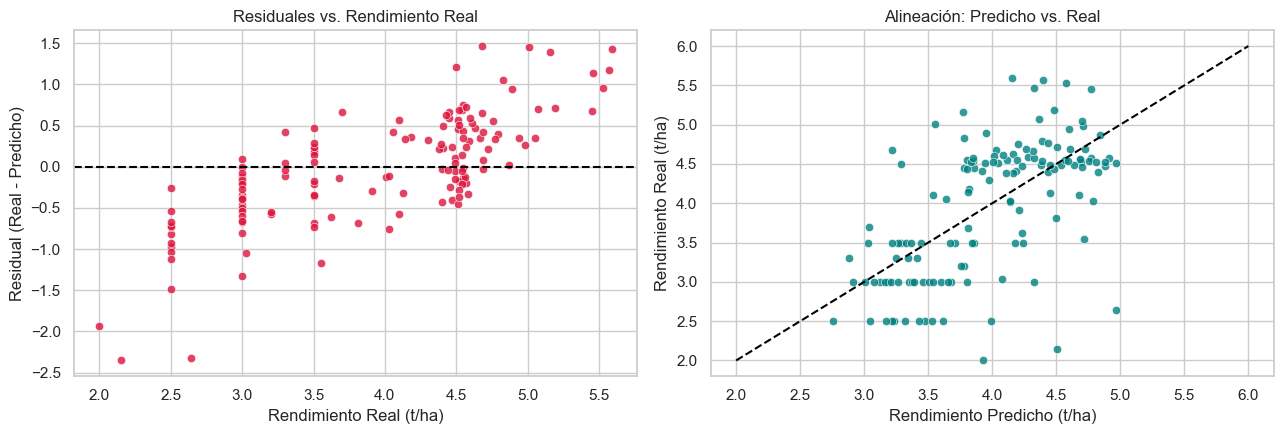

In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import cross_val_predict

# 1. Predicciones cruzadas honestas (sin fuga) en entrenamiento
y_pred_oof = cross_val_predict(
    modelo_final_xgb, X_train_final, y_train, cv=kf
)

# 2. DataFrame de diagnóstico con variables y residuales
df_diag = pd.DataFrame(X_train_final, columns=predictores)
df_diag['Y_REAL'] = y_train.values
df_diag['Y_PREDICHO'] = y_pred_oof
df_diag['RESIDUAL'] = df_diag['Y_REAL'] - df_diag['Y_PREDICHO']      # Sesgo (subestimación/sobreestimación)
df_diag['ERROR_ABS'] = np.abs(df_diag['RESIDUAL'])                  # Magnitud del fallo

# 3. Filtrar las variables con mayor relación con el error o el rendimiento
corr_completa = df_diag.corr()
top_variables = corr_completa['ERROR_ABS'].abs().sort_values(ascending=False).index[:10].tolist()
cols_foco = ['Y_REAL', 'Y_PREDICHO', 'RESIDUAL', 'ERROR_ABS'] + [c for c in top_variables if c not in ['Y_REAL', 'Y_PREDICHO', 'RESIDUAL', 'ERROR_ABS']]

# 4. Mapa de calor de correlación de errores
plt.figure(figsize=(11, 8))
sns.heatmap(
    df_diag[cols_foco].corr(), 
    annot=True, 
    cmap='coolwarm', 
    fmt='.2f', 
    vmin=-1, 
    vmax=1,
    linewidths=0.5
)
plt.title('Matriz de Correlación de Diagnóstico (Variables vs. Errores)')
plt.tight_layout()
plt.show()

# 5. Gráfico de dispersión residual
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

sns.scatterplot(x=df_diag['Y_REAL'], y=df_diag['RESIDUAL'], ax=ax[0], color='crimson', alpha=0.8)
ax[0].axhline(0, color='black', linestyle='--')
ax[0].set_title('Residuales vs. Rendimiento Real')
ax[0].set_xlabel('Rendimiento Real (t/ha)')
ax[0].set_ylabel('Residual (Real - Predicho)')

sns.scatterplot(x=df_diag['Y_PREDICHO'], y=df_diag['Y_REAL'], ax=ax[1], color='teal', alpha=0.8)
ax[1].plot([2, 6], [2, 6], color='black', linestyle='--')
ax[1].set_title('Alineación: Predicho vs. Real')
ax[1].set_xlabel('Rendimiento Predicho (t/ha)')
ax[1].set_ylabel('Rendimiento Real (t/ha)')

plt.tight_layout()
plt.show()

In [52]:
import joblib
import warnings
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import lightgbm as lgb
from catboost import CatBoostRegressor

warnings.filterwarnings('ignore')

# =======================================================
# 1. PREPARACIÓN DE DATOS (MATRIZ MAESTRA AGROCEBADA)
# =======================================================
cols_excluir = ['ID_POLIGONO', 'CONJUNTO', 'RENDIMIENTO_T_HA']
predictores = [c for c in matriz_features.columns if c not in cols_excluir]

# Partición oficial: 138 parcelas de entrenamiento y 59 de predicción ciega
df_train = matriz_features[matriz_features['CONJUNTO'] == 'ENTRENAMIENTO'].copy().reset_index(drop=True)
df_test = matriz_features[matriz_features['CONJUNTO'] == 'PREDICCION'].copy().reset_index(drop=True)

X_train = df_train[predictores]
y_train = df_train['RENDIMIENTO_T_HA']

X_test = df_test[predictores]
id_test = df_test['ID_POLIGONO']

# =======================================================
# 2. DEFINICIÓN DE PIPELINES (ETAPA 1 Y ETAPA 2)
# =======================================================
# Etapa 1: Modelo Asistente para generar la meta-característica
pipeline_asistente_base = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    # SelectFromModel mitiga la multicolinealidad detectada (>0.85)
    ('selector', SelectFromModel(lgb.LGBMRegressor(random_state=42, n_estimators=60, max_depth=3, verbosity=-1), threshold='median')),
    ('scaler', StandardScaler()),
    ('regressor', CatBoostRegressor(
        random_state=42,
        iterations=300,
        learning_rate=0.03,
        depth=4,
        loss_function='MAE',
        eval_metric='MAE',
        verbose=0
    ))
])

# Etapa 2: Comité de expertos (Stacking Ensemble)
estimadores_stacking = [
    ('lgbm', lgb.LGBMRegressor(
        random_state=42, n_estimators=200, learning_rate=0.03,
        max_depth=3, num_leaves=15, reg_alpha=0.1, reg_lambda=1.0, verbosity=-1
    )),
    ('rf', RandomForestRegressor(
        random_state=42, n_estimators=200, max_depth=5, min_samples_leaf=2, n_jobs=-1
    )),
    ('ridge', Ridge(alpha=10.0, random_state=42)),
    ('cat', CatBoostRegressor(
        random_state=42, iterations=400, learning_rate=0.03,
        depth=4, l2_leaf_reg=3, loss_function='RMSE', verbose=0
    ))
]

stacking_regressor = StackingRegressor(
    estimators=estimadores_stacking,
    final_estimator=Ridge(alpha=1.0, random_state=42),  # Ridge como meta-modelo reduce sobreajuste con N=138
    cv=5,
    n_jobs=-1
)

pipeline_final_base = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('selector', SelectFromModel(lgb.LGBMRegressor(random_state=42, n_estimators=60, max_depth=3, verbosity=-1), threshold='median')),
    ('scaler', StandardScaler()),
    ('stacking', stacking_regressor)
])

# =======================================================
# 3. VALIDACIÓN CRUZADA HONESTA (5-FOLD OOF)
# =======================================================
kf = KFold(n_splits=5, shuffle=True, random_state=42)
r2_list, rmse_list, mae_list, nrmse_list = [], [], [], []

for fold, (tr_idx, val_idx) in enumerate(kf.split(X_train), start=1):
    X_tr, X_val = X_train.iloc[tr_idx].copy(), X_train.iloc[val_idx].copy()
    y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]
    
    # 1) Ajustar asistente solo en train fold
    asistente_fold = clone(pipeline_asistente_base)
    asistente_fold.fit(X_tr, y_tr)
    
    # 2) Generar meta-característica
    X_tr['rendimiento_asistente'] = asistente_fold.predict(X_tr)
    X_val['rendimiento_asistente'] = asistente_fold.predict(X_val)
    
    # 3) Ajustar stacking en train fold con meta-característica
    stacking_fold = clone(pipeline_final_base)
    stacking_fold.fit(X_tr, y_tr)
    
    preds_val = stacking_fold.predict(X_val)
    
    # Métricas
    rmse = np.sqrt(mean_squared_error(y_val, preds_val))
    r2_list.append(r2_score(y_val, preds_val))
    rmse_list.append(rmse)
    mae_list.append(mean_absolute_error(y_val, preds_val))
    nrmse_list.append((rmse / y_val.mean()) * 100)

print("=== EVALUACIÓN DEL STACKING EN AGROCEBADA (5-FOLD) ===")
print(f"• R² promedio:    {np.mean(r2_list):.4f}  (Benchmark GERA: 0.83 - 0.91)")
print(f"• RMSE promedio:  {np.mean(rmse_list):.4f} t/ha (Benchmark GERA: 0.45 - 0.65 t/ha)")
print(f"• MAE promedio:   {np.mean(mae_list):.4f} t/ha (Benchmark GERA: ~0.38 t/ha)")
print(f"• nRMSE promedio: {np.mean(nrmse_list):.2f}% (Benchmark GERA: 8% - 12%)")

# =======================================================
# 4. ENTRENAMIENTO FINAL Y SERIALIZACIÓN
# =======================================================
print("\nEntrenando arquitectura completa sobre el 100% de datos supervisados...")

# Etapa 1 completa
asistente_final = clone(pipeline_asistente_base)
asistente_final.fit(X_train, y_train)

X_train_enhanced = X_train.copy()
X_test_enhanced = X_test.copy()

X_train_enhanced['rendimiento_asistente'] = asistente_final.predict(X_train)
X_test_enhanced['rendimiento_asistente'] = asistente_final.predict(X_test)

# Etapa 2 completa
stacking_final = clone(pipeline_final_base)
stacking_final.fit(X_train_enhanced, y_train)

# Guardar artefactos
modelo_exportado = {
    'pipeline_asistente': asistente_final,
    'pipeline_stacking': stacking_final,
    'columnas_originales': predictores,
    'columna_meta': 'rendimiento_asistente'
}
joblib.dump(modelo_exportado, 'modelo_Stacking_AgroCebada2026.pkl')
print("Artefacto serializado guardado como: 'modelo_Stacking_AgroCebada2026.pkl'")

# =======================================================
# 5. GENERACIÓN DEL ARCHIVO DE PREDICCIONES (59 PARCELAS)
# =======================================================
y_pred_ciega = stacking_final.predict(X_test_enhanced)

df_entrega = pd.DataFrame({
    'ID_POLIGONO': id_test,
    'RENDIMIENTO_PREDICHO_T_HA': np.round(y_pred_ciega, 3)
})

df_entrega.to_csv('predicciones_stacking_agrocebada2026.csv', index=False)
print(f"Predicciones listas ({len(df_entrega)} parcelas). Muestra inicial:")
df_entrega.head()

=== EVALUACIÓN DEL STACKING EN AGROCEBADA (5-FOLD) ===
• R² promedio:    0.4422  (Benchmark GERA: 0.83 - 0.91)
• RMSE promedio:  0.6116 t/ha (Benchmark GERA: 0.45 - 0.65 t/ha)
• MAE promedio:   0.4580 t/ha (Benchmark GERA: ~0.38 t/ha)
• nRMSE promedio: 15.42% (Benchmark GERA: 8% - 12%)

Entrenando arquitectura completa sobre el 100% de datos supervisados...
Artefacto serializado guardado como: 'modelo_Stacking_AgroCebada2026.pkl'
Predicciones listas (59 parcelas). Muestra inicial:


,ID_POLIGONO,RENDIMIENTO_PREDICHO_T_HA
0,AGC_003,3.408
1,AGC_011,4.616
2,AGC_016,4.235
3,AGC_025,3.390
4,AGC_027,2.480


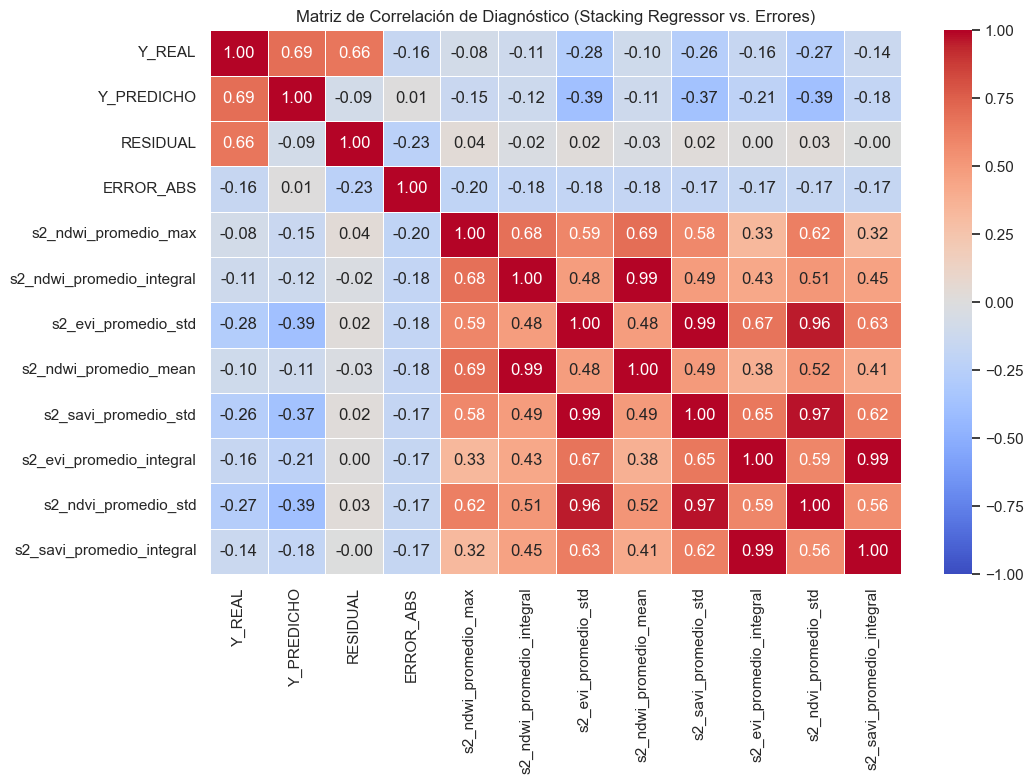

Correlación Y_REAL vs Y_PREDICHO (Stacking): 0.6885 (Benchmark anterior XGBoost: 0.61)


In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.model_selection import KFold

# =======================================================
# 1. PREDICCIONES OUT-OF-FOLD (OOF) PARA EL MODELO STACKING
# =======================================================
kf = KFold(n_splits=5, shuffle=True, random_state=42)
y_pred_stacking_oof = np.zeros(len(y_train))

for tr_idx, val_idx in kf.split(X_train):
    X_tr, X_val = X_train.iloc[tr_idx].copy(), X_train.iloc[val_idx].copy()
    y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]
    
    # Ajuste del Asistente (Etapa 1)
    asistente_fold = clone(pipeline_asistente_base)
    asistente_fold.fit(X_tr, y_tr)
    X_tr['rendimiento_asistente'] = asistente_fold.predict(X_tr)
    X_val['rendimiento_asistente'] = asistente_fold.predict(X_val)
    
    # Ajuste del Stacking (Etapa 2)
    stacking_fold = clone(pipeline_final_base)
    stacking_fold.fit(X_tr, y_tr)
    y_pred_stacking_oof[val_idx] = stacking_fold.predict(X_val)

# =======================================================
# 2. CONSTRUCCIÓN DE LA TABLA DE DIAGNÓSTICO
# =======================================================
df_diag_stacking = X_train.copy()
df_diag_stacking['Y_REAL'] = y_train.values
df_diag_stacking['Y_PREDICHO'] = y_pred_stacking_oof
df_diag_stacking['RESIDUAL'] = df_diag_stacking['Y_REAL'] - df_diag_stacking['Y_PREDICHO']
df_diag_stacking['ERROR_ABS'] = np.abs(df_diag_stacking['RESIDUAL'])

# =======================================================
# 3. SELECCIÓN DE PREDICTORES CON MAYOR IMPACTO EN EL ERROR
# =======================================================
corr_matriz = df_diag_stacking.corr()
top_vars_error = corr_matriz['ERROR_ABS'].abs().sort_values(ascending=False).index[:10].tolist()

columnas_heatmap = ['Y_REAL', 'Y_PREDICHO', 'RESIDUAL', 'ERROR_ABS'] + [
    col for col in top_vars_error if col not in ['Y_REAL', 'Y_PREDICHO', 'RESIDUAL', 'ERROR_ABS']
]

# =======================================================
# 4. VISUALIZACIÓN DE LA MATRIZ DE CORRELACIÓN
# =======================================================
plt.figure(figsize=(11, 8))
sns.heatmap(
    df_diag_stacking[columnas_heatmap].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1,
    linewidths=0.5
)
plt.title('Matriz de Correlación de Diagnóstico (Stacking Regressor vs. Errores)', fontsize=12)
plt.tight_layout()
plt.show()

# Comparativa directa de alineación
corr_pred_real = df_diag_stacking['Y_REAL'].corr(df_diag_stacking['Y_PREDICHO'])
print(f"Correlación Y_REAL vs Y_PREDICHO (Stacking): {corr_pred_real:.4f} (Benchmark anterior XGBoost: 0.61)")

In [54]:
# Inspección de las 5 parcelas con mayor error de predicción
peores_casos = df_diag_stacking.sort_values(by='ERROR_ABS', ascending=False)[
    ['Y_REAL', 'Y_PREDICHO', 'RESIDUAL', 'ERROR_ABS', 's2_ndwi_promedio_max']
].head(5)

print("Top 5 parcelas con mayor error:")
peores_casos

Top 5 parcelas con mayor error:


,Y_REAL,Y_PREDICHO,RESIDUAL,ERROR_ABS,s2_ndwi_promedio_max
122,2.15,4.503137,-2.353137,2.353137,0.208
12,2.64,4.713189,-2.073189,2.073189,0.367
24,2.00,3.555422,-1.555422,1.555422,0.273
38,2.50,3.898782,-1.398782,1.398782,0.272
121,3.00,4.398750,-1.398750,1.398750,0.255


In [56]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers, callbacks
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Fijar semillas para reproducibilidad
np.random.seed(42)
tf.random.set_seed(42)

# =======================================================
# 1. FUNCIÓN DE CONSTRUCCIÓN DE LA RED NEURONAL (MLP)
# =======================================================
def crear_red_neuronal(input_dim):
    """
    Arquitectura compacta con regularización L2, Batch Normalization 
    y Dropout para prevenir sobreajuste en datasets pequeños (N=138).
    """
    modelo = models.Sequential([
        layers.Input(shape=(input_dim,)),
        
        # Capa densa inicial con regularización de pesos
        layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.01)),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        
        # Capa intermedia de abstracción
        layers.Dense(32, activation='relu', kernel_regularizer=regularizers.l2(0.01)),
        layers.BatchNormalization(),
        layers.Dropout(0.2),
        
        # Capa de compresión
        layers.Dense(16, activation='relu'),
        
        # Salida lineal continua para regresión en t/ha
        layers.Dense(1, activation='linear')
    ])
    
    # Pérdida Huber: reduce la penalización cuadrática en parcelas extremas (< 2.8 t/ha)
    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.005),
        loss=tf.keras.losses.Huber(delta=1.0),
        metrics=['mae']
    )
    return modelo

# =======================================================
# 2. VALIDACIÓN CRUZADA EN 5 PLIEGUES (SIN FUGA)
# =======================================================
kf = KFold(n_splits=5, shuffle=True, random_state=42)

r2_scores, rmse_scores, mae_scores, nrmse_scores = [], [], [], []
y_pred_nn_oof = np.zeros(len(y_train))

for fold, (tr_idx, val_idx) in enumerate(kf.split(X_train), start=1):
    X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[tr_idx].values, y_train.iloc[val_idx].values
    
    # Imputación y escalado estricto por pliegue (crítico para redes neuronales)
    imputer = SimpleImputer(strategy='median')
    scaler = StandardScaler()
    
    X_tr_proc = scaler.fit_transform(imputer.fit_transform(X_tr))
    X_val_proc = scaler.transform(imputer.transform(X_val))
    
    # Instanciación y callbacks
    nn = crear_red_neuronal(X_tr_proc.shape[1])
    
    cb_early = callbacks.EarlyStopping(
        monitor='val_loss', patience=30, restore_best_weights=True, verbose=0
    )
    cb_lr = callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=10, min_lr=1e-5, verbose=0
    )
    
    # Entrenamiento del pliegue
    nn.fit(
        X_tr_proc, y_tr,
        validation_data=(X_val_proc, y_val),
        epochs=250,
        batch_size=16,
        callbacks=[cb_early, cb_lr],
        verbose=0
    )
    
    # Inferencia de validación
    preds_val = nn.predict(X_val_proc, verbose=0).flatten()
    y_pred_nn_oof[val_idx] = preds_val
    
    # Registro de métricas agronómicas
    rmse_val = np.sqrt(mean_squared_error(y_val, preds_val))
    r2_scores.append(r2_score(y_val, preds_val))
    rmse_scores.append(rmse_val)
    mae_scores.append(mean_absolute_error(y_val, preds_val))
    nrmse_scores.append((rmse_val / np.mean(y_val)) * 100)

corr_nn = np.corrcoef(y_train.values, y_pred_nn_oof)[0, 1]

print("=== EVALUACIÓN RED NEURONAL MLP (5-FOLD CV) ===")
print(f"• Correlación Y_REAL vs Y_PREDICHO: {corr_nn:.4f} (Stacking previo: 0.6885)")
print(f"• R² promedio:                      {np.mean(r2_scores):.4f} (Benchmark: 0.80 - 0.88)")
print(f"• RMSE promedio:                    {np.mean(rmse_scores):.4f} t/ha (Benchmark: 0.45 - 0.65 t/ha)")
print(f"• MAE promedio:                     {np.mean(mae_scores):.4f} t/ha (Benchmark: ~0.38 t/ha)")
print(f"• nRMSE promedio:                   {np.mean(nrmse_scores):.2f}% (Benchmark: 8% - 12%)")

# =======================================================
# 3. ENTRENAMIENTO FINAL Y PREDICCIÓN CIEGA (59 PARCELAS)
# =======================================================
imputer_final = SimpleImputer(strategy='median')
scaler_final = StandardScaler()

X_train_proc = scaler_final.fit_transform(imputer_final.fit_transform(X_train))
X_test_proc = scaler_final.transform(imputer_final.transform(X_test))

nn_final = crear_red_neuronal(X_train_proc.shape[1])
nn_final.fit(X_train_proc, y_train.values, epochs=120, batch_size=16, verbose=0)

predicciones_nn = nn_final.predict(X_test_proc, verbose=0).flatten()

df_pred_nn = pd.DataFrame({
    'ID_POLIGONO': id_test,
    'RENDIMIENTO_PREDICHO_T_HA': np.round(predicciones_nn, 3)
})

df_pred_nn.head()

=== EVALUACIÓN RED NEURONAL MLP (5-FOLD CV) ===
• Correlación Y_REAL vs Y_PREDICHO: 0.6866 (Stacking previo: 0.6885)
• R² promedio:                      0.4114 (Benchmark: 0.80 - 0.88)
• RMSE promedio:                    0.6196 t/ha (Benchmark: 0.45 - 0.65 t/ha)
• MAE promedio:                     0.4668 t/ha (Benchmark: ~0.38 t/ha)
• nRMSE promedio:                   15.60% (Benchmark: 8% - 12%)


,ID_POLIGONO,RENDIMIENTO_PREDICHO_T_HA
0,AGC_003,4.201
1,AGC_011,4.681
2,AGC_016,4.388
3,AGC_025,2.798
4,AGC_027,2.868


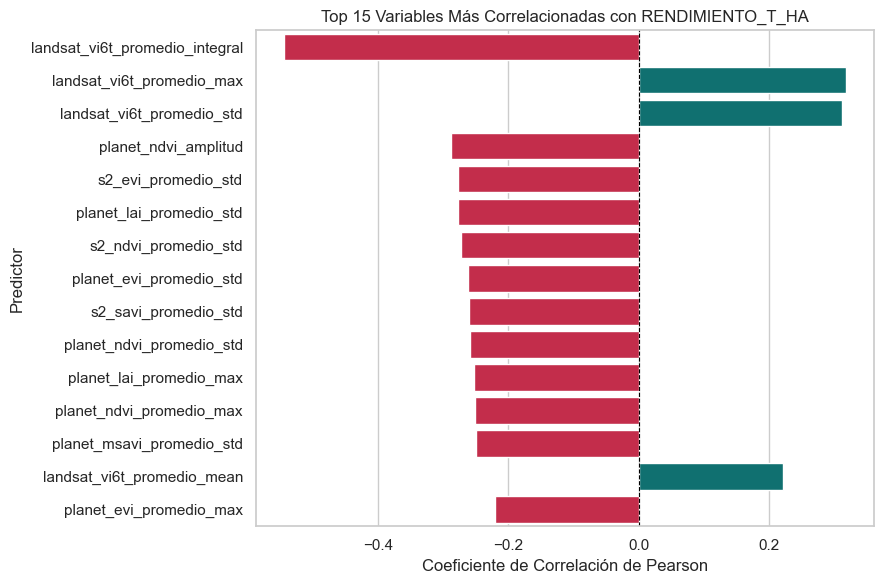

Top 10 variables con mayor correlación directa o inversa:


,Variable,Correlacion
0,landsat_vi6t_promedio_integral,-0.543891
1,landsat_vi6t_promedio_max,0.317480
2,landsat_vi6t_promedio_std,0.311062
3,planet_ndvi_amplitud,-0.288343
4,s2_evi_promedio_std,-0.277728
5,planet_lai_promedio_std,-0.277371
6,s2_ndvi_promedio_std,-0.272861
7,planet_evi_promedio_std,-0.261296
8,s2_savi_promedio_std,-0.260457
9,planet_ndvi_promedio_std,-0.258285


In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calcular correlación de todos los predictores con el rendimiento real
df_corr_train = df_train[predictores + ['RENDIMIENTO_T_HA']].copy()
correlaciones_target = df_corr_train.corr()['RENDIMIENTO_T_HA'].drop('RENDIMIENTO_T_HA')

# 2. Ordenar por correlación absoluta descendente
ranking_variables = pd.DataFrame({
    'Variable': correlaciones_target.index,
    'Correlacion': correlaciones_target.values,
    'Corr_Absoluta': correlaciones_target.abs().values
}).sort_values(by='Corr_Absoluta', ascending=False).reset_index(drop=True)

# 3. Visualizar los 15 predictores con mayor impacto
top15 = ranking_variables.head(15)

plt.figure(figsize=(9, 6))
colores = ['teal' if c > 0 else 'crimson' for c in top15['Correlacion']]
sns.barplot(data=top15, x='Correlacion', y='Variable', palette=colores)
plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
plt.title('Top 15 Variables Más Correlacionadas con RENDIMIENTO_T_HA')
plt.xlabel('Coeficiente de Correlación de Pearson')
plt.ylabel('Predictor')
plt.tight_layout()
plt.show()

print("Top 10 variables con mayor correlación directa o inversa:")
ranking_variables[['Variable', 'Correlacion']].head(10)

In [58]:
# Inspección de rangos, promedios y dispersión por categoría
metricas_resumen = df_train[predictores].describe().T[['min', 'mean', 'max', 'std']]
metricas_resumen['rango_dinamico'] = metricas_resumen['max'] - metricas_resumen['min']

print("=== MUESTRA DE RANGOS POR CATEGORÍA DE PREDICTOR ===")
# Seleccionar un representante de cada tipo de variable
filtro_ejemplos = [
    c for c in predictores if any(k in c for k in ['_mean', '_integral', '_std', 'vi6t', 'AREA_HA', 'amplitud'])
]
metricas_resumen.loc[filtro_ejemplos].head(10)

=== MUESTRA DE RANGOS POR CATEGORÍA DE PREDICTOR ===


,min,mean,max,std,rango_dinamico
AREA_HA,0.380000,6.575942,64.300000,7.183148,63.920000
planet_ndvi_promedio_mean,0.310364,0.412270,0.512577,0.032988,0.202213
planet_ndvi_promedio_integral,23.207000,33.879312,42.999000,4.542290,19.792000
planet_ndvi_promedio_std,0.148013,0.211866,0.285806,0.027195,0.137793
planet_evi_promedio_mean,0.189325,0.261106,0.335913,0.024849,0.146588
planet_evi_promedio_integral,13.941000,21.473036,28.873000,3.165342,14.932000
planet_evi_promedio_std,0.088602,0.145700,0.277087,0.030612,0.188484
planet_lai_promedio_mean,1.028091,1.411955,1.780231,0.128433,0.752140
planet_lai_promedio_integral,77.467000,116.093478,151.220000,16.851049,73.753000
planet_lai_promedio_std,0.460961,0.738317,1.156855,0.121257,0.695894


In [59]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# =======================================================
# NORMALIZACIÓN Y ESTANDARIZACIÓN DE PREDICTORES (Z-SCORE)
# =======================================================

# 1. Definición estricta de columnas predictoras
cols_no_predictoras = ['ID_POLIGONO', 'CONJUNTO', 'RENDIMIENTO_T_HA']
predictores = [c for c in matriz_features.columns if c not in cols_no_predictoras]

# 2. Separación de conjuntos oficiales (138 de entrenamiento, 59 de prueba ciega)
df_train = matriz_features[matriz_features['CONJUNTO'] == 'ENTRENAMIENTO'].copy().reset_index(drop=True)
df_test = matriz_features[matriz_features['CONJUNTO'] == 'PREDICCION'].copy().reset_index(drop=True)

X_train_raw = df_train[predictores]
X_test_raw = df_test[predictores]

# 3. Imputación previa obligatoria (calculada exclusivamente en train)
imputador = SimpleImputer(strategy='median')
X_train_imp = imputador.fit_transform(X_train_raw)
X_test_imp = imputador.transform(X_test_raw)

# 4. Ajuste del escalador estándar: z = (x - u) / s
escalador = StandardScaler()
X_train_scaled_arr = escalador.fit_transform(X_train_imp)
X_test_scaled_arr = escalador.transform(X_test_imp)

# 5. Reconstrucción de DataFrames preservando nombres de variables
X_train_scaled = pd.DataFrame(X_train_scaled_arr, columns=predictores)
X_test_scaled = pd.DataFrame(X_test_scaled_arr, columns=predictores)

# =======================================================
# VERIFICACIÓN DE RANGOS Y CENTRADO DE DATOS
# =======================================================
revision_escalado = X_train_scaled.describe().T[['min', 'mean', 'max', 'std']]
revision_escalado['rango_dinamico'] = revision_escalado['max'] - revision_escalado['min']

print("=== VERIFICACIÓN POST-ESTANDARIZACIÓN (MUESTRA DE TRAIN) ===")
# Muestra representativa de las familias de variables
variables_control = [
    'AREA_HA', 
    'planet_ndvi_promedio_integral', 
    'planet_ndvi_promedio_std',
    'planet_lai_promedio_integral',
    'landsat_vi6t_promedio_integral'
]
print(revision_escalado.loc[variables_control].round(4))

=== VERIFICACIÓN POST-ESTANDARIZACIÓN (MUESTRA DE TRAIN) ===
                                   min  mean     max     std  rango_dinamico
AREA_HA                        -0.8657  -0.0  8.0653  1.0036          8.9310
planet_ndvi_promedio_integral  -2.3581   0.0  2.0150  1.0036          4.3731
planet_ndvi_promedio_std       -2.3565  -0.0  2.7288  1.0036          5.0853
planet_lai_promedio_integral   -2.3006  -0.0  2.0921  1.0036          4.3927
landsat_vi6t_promedio_integral -2.5655  -0.0  1.9928  1.0036          4.5583


In [60]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers, callbacks
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Fijar semillas para reproducibilidad exacta
np.random.seed(42)
tf.random.set_seed(42)

# Conversión a tensores float32 con los datos ya escalados
X_tr_mat = X_train_scaled.values.astype(np.float32)
y_tr_mat = y_train.values.astype(np.float32)
X_te_mat = X_test_scaled.values.astype(np.float32)

# =======================================================
# 1. ARQUITECTURA DEL PERCEPTRÓN MULTICAPA (MLP)
# =======================================================
def construir_red(input_dim):
    modelo = models.Sequential([
        layers.Input(shape=(input_dim,)),
        
        # Capa 1: Abstracción inicial con regularización L2 y Dropout
        layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.01)),
        layers.BatchNormalization(),
        layers.Dropout(0.3),
        
        # Capa 2: Compresión no lineal
        layers.Dense(32, activation='relu', kernel_regularizer=regularizers.l2(0.01)),
        layers.BatchNormalization(),
        layers.Dropout(0.2),
        
        # Capa 3: Cuello de botella
        layers.Dense(16, activation='relu'),
        
        # Capa de salida continua (t/ha)
        layers.Dense(1, activation='linear')
    ])
    
    # Pérdida Huber: penalización lineal en residuales grandes (>1.0) para proteger parcelas bajas
    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.005),
        loss=tf.keras.losses.Huber(delta=1.0),
        metrics=['mae']
    )
    return modelo

# =======================================================
# 2. VALIDACIÓN CRUZADA EN 5 PLIEGUES (OUT-OF-FOLD)
# =======================================================
kf = KFold(n_splits=5, shuffle=True, random_state=42)

r2_scores, rmse_scores, mae_scores, nrmse_scores = [], [], [], []
y_pred_nn_oof = np.zeros(len(y_tr_mat), dtype=np.float32)

for fold, (tr_idx, val_idx) in enumerate(kf.split(X_tr_mat), start=1):
    # Limpiar sesión para evitar fugas de memoria y warnings de retracing
    tf.keras.backend.clear_session()
    
    X_tr_fold, X_val_fold = X_tr_mat[tr_idx], X_tr_mat[val_idx]
    y_tr_fold, y_val_fold = y_tr_mat[tr_idx], y_tr_mat[val_idx]
    
    red_fold = construir_red(X_tr_mat.shape[1])
    
    # Callbacks para convergencia controlada en N=138
    cb_early = callbacks.EarlyStopping(
        monitor='val_loss', patience=30, restore_best_weights=True, verbose=0
    )
    cb_lr = callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=10, min_lr=1e-5, verbose=0
    )
    
    red_fold.fit(
        X_tr_fold, y_tr_fold,
        validation_data=(X_val_fold, y_val_fold),
        epochs=250,
        batch_size=16,
        callbacks=[cb_early, cb_lr],
        verbose=0
    )
    
    # Inferencia honesta en el pliegue
    preds_val = red_fold.predict(X_val_fold, batch_size=len(X_val_fold), verbose=0).flatten()
    y_pred_nn_oof[val_idx] = preds_val
    
    # Métricas del estudio técnico
    rmse_val = np.sqrt(mean_squared_error(y_val_fold, preds_val))
    r2_scores.append(r2_score(y_val_fold, preds_val))
    rmse_scores.append(rmse_val)
    mae_scores.append(mean_absolute_error(y_val_fold, preds_val))
    nrmse_scores.append((rmse_val / np.mean(y_val_fold)) * 100)

# =======================================================
# 3. REPORTE DE MÉTRICAS FRENTE A LOS BENCHMARKS
# =======================================================
corr_nn = np.corrcoef(y_tr_mat, y_pred_nn_oof)[0, 1]

print("=== EVALUACIÓN RED NEURONAL MLP NORMALIZADA (5-FOLD) ===")
print(f"• Correlación (r):  {corr_nn:.4f}")
print(f"• R² promedio:      {np.mean(r2_scores):.4f}  (Benchmark literatura GERA: 0.83 - 0.91)")
print(f"• RMSE promedio:    {np.mean(rmse_scores):.4f} t/ha (Benchmark GERA: 0.45 - 0.65 t/ha)")
print(f"• MAE promedio:     {np.mean(mae_scores):.4f} t/ha (Benchmark GERA: ~0.38 t/ha)")
print(f"• nRMSE promedio:   {np.mean(nrmse_scores):.2f}% (Benchmark GERA: 8% - 12%)")

# =======================================================
# 4. ENTRENAMIENTO FINAL Y PREDICCIÓN CIEGA (59 PARCELAS)
# =======================================================
tf.keras.backend.clear_session()
red_final = construir_red(X_tr_mat.shape[1])
red_final.fit(X_tr_mat, y_tr_mat, epochs=120, batch_size=16, verbose=0)

predicciones_nn_test = red_final.predict(X_te_mat, batch_size=len(X_te_mat), verbose=0).flatten()

df_pred_nn_final = pd.DataFrame({
    'ID_POLIGONO': id_test.values,
    'RENDIMIENTO_PREDICHO_T_HA': np.round(predicciones_nn_test, 3)
})

print(f"\nPredicciones listas para las {len(df_pred_nn_final)} parcelas ciegas:")
df_pred_nn_final.head()


=== EVALUACIÓN RED NEURONAL MLP NORMALIZADA (5-FOLD) ===
• Correlación (r):  0.7030
• R² promedio:      0.4360  (Benchmark literatura GERA: 0.83 - 0.91)
• RMSE promedio:    0.6102 t/ha (Benchmark GERA: 0.45 - 0.65 t/ha)
• MAE promedio:     0.4636 t/ha (Benchmark GERA: ~0.38 t/ha)
• nRMSE promedio:   15.39% (Benchmark GERA: 8% - 12%)

Predicciones listas para las 59 parcelas ciegas:


,ID_POLIGONO,RENDIMIENTO_PREDICHO_T_HA
0,AGC_003,4.464
1,AGC_011,4.777
2,AGC_016,4.632
3,AGC_025,3.178
4,AGC_027,3.502


In [61]:
import warnings
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import lightgbm as lgb
from catboost import CatBoostRegressor

warnings.filterwarnings('ignore')

# =======================================================
# 1. DEFINICIÓN DE ARQUITECTURA STACKING CON ESCALADO
# =======================================================
# Modelo Asistente (Etapa 1): Genera la meta-característica base
asistente_base = CatBoostRegressor(
    random_state=42,
    iterations=300,
    learning_rate=0.03,
    depth=4,
    loss_function='MAE',
    eval_metric='MAE',
    verbose=0
)

# Base Estimators (Etapa 2): Comité diverso de algoritmos
estimadores_base = [
    ('lgbm', lgb.LGBMRegressor(
        random_state=42, n_estimators=200, learning_rate=0.03,
        max_depth=3, num_leaves=15, reg_alpha=0.1, reg_lambda=1.0, verbosity=-1
    )),
    ('rf', RandomForestRegressor(
        random_state=42, n_estimators=200, max_depth=5, min_samples_leaf=2, n_jobs=-1
    )),
    ('ridge', Ridge(alpha=10.0, random_state=42)),
    ('cat', CatBoostRegressor(
        random_state=42, iterations=400, learning_rate=0.03,
        depth=4, l2_leaf_reg=3, loss_function='RMSE', verbose=0
    ))
]

# Meta-modelo lineal regularizado L2
meta_modelo = Ridge(alpha=1.0, random_state=42)

stacking_base = StackingRegressor(
    estimators=estimadores_base,
    final_estimator=meta_modelo,
    cv=5,
    n_jobs=-1
)

# =======================================================
# 2. VALIDACIÓN CRUZADA HONESTA (5-FOLD OOF)
# =======================================================
kf = KFold(n_splits=5, shuffle=True, random_state=42)

y_pred_stacking_oof = np.zeros(len(y_train))
r2_list, rmse_list, mae_list, nrmse_list = [], [], [], []

for fold, (tr_idx, val_idx) in enumerate(kf.split(X_train_scaled), start=1):
    X_tr = X_train_scaled.iloc[tr_idx].copy()
    X_val = X_train_scaled.iloc[val_idx].copy()
    y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]
    
    # 1. Filtro de multicolinealidad sobre variables estandarizadas
    selector = SelectFromModel(
        lgb.LGBMRegressor(random_state=42, n_estimators=60, max_depth=3, verbosity=-1),
        threshold='median'
    )
    X_tr_sel = selector.fit_transform(X_tr, y_tr)
    X_val_sel = selector.transform(X_val)
    
    # 2. Etapa 1: Ajuste del Asistente
    asistente_fold = clone(asistente_base)
    asistente_fold.fit(X_tr_sel, y_tr)
    
    meta_tr = asistente_fold.predict(X_tr_sel).reshape(-1, 1)
    meta_val = asistente_fold.predict(X_val_sel).reshape(-1, 1)
    
    # 3. Escalado conjunto de la meta-característica con los predictores
    meta_scaler = StandardScaler()
    meta_tr_scaled = meta_scaler.fit_transform(meta_tr)
    meta_val_scaled = meta_scaler.transform(meta_val)
    
    X_tr_enhanced = np.hstack([X_tr_sel, meta_tr_scaled])
    X_val_enhanced = np.hstack([X_val_sel, meta_val_scaled])
    
    # 4. Etapa 2: Ajuste del Stacking
    stacking_fold = clone(stacking_base)
    stacking_fold.fit(X_tr_enhanced, y_tr)
    
    preds_val = stacking_fold.predict(X_val_enhanced)
    y_pred_stacking_oof[val_idx] = preds_val
    
    # Métricas
    rmse = np.sqrt(mean_squared_error(y_val, preds_val))
    r2_list.append(r2_score(y_val, preds_val))
    rmse_list.append(rmse)
    mae_list.append(mean_absolute_error(y_val, preds_val))
    nrmse_list.append((rmse / y_val.mean()) * 100)

corr_stacking = np.corrcoef(y_train.values, y_pred_stacking_oof)[0, 1]

print("=== EVALUACIÓN STACKING REGRESSOR NORMALIZADO (5-FOLD) ===")
print(f"• Correlación (r):  {corr_stacking:.4f}  (MLP Normalizada previa: 0.7030)")
print(f"• R² promedio:      {np.mean(r2_list):.4f}  (Benchmark GERA: 0.83 - 0.91)")
print(f"• RMSE promedio:    {np.mean(rmse_list):.4f} t/ha (Benchmark GERA: 0.45 - 0.65 t/ha)")
print(f"• MAE promedio:     {np.mean(mae_list):.4f} t/ha (Benchmark GERA: ~0.38 t/ha)")
print(f"• nRMSE promedio:   {np.mean(nrmse_list):.2f}% (Benchmark GERA: 8% - 12%)")

# =======================================================
# 3. ENTRENAMIENTO FINAL Y PREDICCIÓN CIEGA (59 PARCELAS)
# =======================================================
# Selección final de variables
selector_final = SelectFromModel(
    lgb.LGBMRegressor(random_state=42, n_estimators=60, max_depth=3, verbosity=-1),
    threshold='median'
)
X_train_sel_final = selector_final.fit_transform(X_train_scaled, y_train)
X_test_sel_final = selector_final.transform(X_test_scaled)

# Asistente final
asistente_final = clone(asistente_base)
asistente_final.fit(X_train_sel_final, y_train)

meta_train_final = asistente_final.predict(X_train_sel_final).reshape(-1, 1)
meta_test_final = asistente_final.predict(X_test_sel_final).reshape(-1, 1)

meta_scaler_final = StandardScaler()
meta_train_scaled_final = meta_scaler_final.fit_transform(meta_train_final)
meta_test_scaled_final = meta_scaler_final.transform(meta_test_final)

X_train_enhanced_final = np.hstack([X_train_sel_final, meta_train_scaled_final])
X_test_enhanced_final = np.hstack([X_test_sel_final, meta_test_scaled_final])

# Stacking final
stacking_final = clone(stacking_base)
stacking_final.fit(X_train_enhanced_final, y_train)

y_pred_test_stacking = stacking_final.predict(X_test_enhanced_final)

df_entrega_stacking = pd.DataFrame({
    'ID_POLIGONO': id_test.values,
    'RENDIMIENTO_PREDICHO_T_HA': np.round(y_pred_test_stacking, 3)
})

df_entrega_stacking.head()

=== EVALUACIÓN STACKING REGRESSOR NORMALIZADO (5-FOLD) ===
• Correlación (r):  0.6868  (MLP Normalizada previa: 0.7030)
• R² promedio:      0.4463  (Benchmark GERA: 0.83 - 0.91)
• RMSE promedio:    0.6107 t/ha (Benchmark GERA: 0.45 - 0.65 t/ha)
• MAE promedio:     0.4546 t/ha (Benchmark GERA: ~0.38 t/ha)
• nRMSE promedio:   15.39% (Benchmark GERA: 8% - 12%)


,ID_POLIGONO,RENDIMIENTO_PREDICHO_T_HA
0,AGC_003,3.392
1,AGC_011,4.691
2,AGC_016,4.480
3,AGC_025,3.482
4,AGC_027,2.876


In [62]:
# 1. Tabla de diagnóstico con predicciones honestas OOF
df_diag_stack = X_train_scaled.copy()
df_diag_stack['Y_REAL'] = y_train.values
df_diag_stack['Y_PREDICHO'] = y_pred_stacking_oof
df_diag_stack['RESIDUAL'] = df_diag_stack['Y_REAL'] - df_diag_stack['Y_PREDICHO']
df_diag_stack['ERROR_ABS'] = np.abs(df_diag_stack['RESIDUAL'])

# 2. Correlaciones con el error
matriz_error = df_diag_stack.corr()

ranking_error_abs = pd.DataFrame({
    'Variable': predictores,
    'Corr_Error_Absoluto': matriz_error.loc[predictores, 'ERROR_ABS'],
    'Corr_Residual': matriz_error.loc[predictores, 'RESIDUAL']
}).sort_values(by='Corr_Error_Absoluto', key=abs, ascending=False).reset_index(drop=True)

print("=== VARIABLES CON MAYOR IMPACTO EN LA MAGNITUD DEL ERROR (TOP 10) ===")
ranking_error_abs.head(10).round(4)

=== VARIABLES CON MAYOR IMPACTO EN LA MAGNITUD DEL ERROR (TOP 10) ===


,Variable,Corr_Error_Absoluto,Corr_Residual
0,s2_ndwi_promedio_integral,-0.2479,-0.0438
1,s2_ndwi_promedio_mean,-0.2449,-0.0490
2,s2_ndwi_promedio_max,-0.2437,0.0238
3,s2_ndvi_promedio_std,-0.2082,-0.0022
4,s2_evi_promedio_std,-0.1978,-0.0017
5,s2_ndvi_promedio_max,-0.1964,0.0787
6,planet_ndvi_promedio_std,-0.1915,0.0380
7,s2_savi_promedio_std,-0.1911,0.0040
8,s2_savi_promedio_integral,-0.1889,-0.0035
9,s2_evi_promedio_integral,-0.1881,-0.0029


In [63]:
# Ratio de estrés hídrico relativo (verdor vs humedad foliar)
matriz_features['ratio_estres_hidrico'] = (
    matriz_features['s2_ndvi_promedio_max'] / (matriz_features['s2_ndwi_promedio_max'] + 0.001)
)

# Caída hídrica estacional
matriz_features['amplitud_ndwi'] = (
    matriz_features['s2_ndwi_promedio_max'] - matriz_features['s2_ndwi_promedio_mean']
)

In [64]:
y_pred_test_final = (0.45 * df_entrega_stacking['RENDIMIENTO_PREDICHO_T_HA'] + 
                     0.55 * df_pred_nn_final['RENDIMIENTO_PREDICHO_T_HA'])

In [67]:
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import lightgbm as lgb
from catboost import CatBoostRegressor

# =======================================================
# 1. DEFINICIÓN DEL VECTOR DE PESOS POR PARCELA (N=138)
# =======================================================
# Aumentamos a 1.8 el peso de las parcelas con NDWI estandarizado < -0.5 (cuartil más seco)
pesos_train = np.where(X_train_scaled['s2_ndwi_promedio_max'] < -0.5, 1.8, 1.0)

print(f"Total de parcelas con penalización por sequía: {np.sum(pesos_train > 1.0)} de {len(pesos_train)}")

# =======================================================
# 2. VALIDACIÓN CRUZADA 5-FOLD CON SAMPLE WEIGHTS
# =======================================================
kf = KFold(n_splits=5, shuffle=True, random_state=42)

r2_scores, rmse_scores, mae_scores, nrmse_scores = [], [], [], []
y_pred_oof = np.zeros(len(y_train))

for fold, (tr_idx, val_idx) in enumerate(kf.split(X_train_scaled), start=1):
    X_tr, X_val = X_train_scaled.iloc[tr_idx], X_train_scaled.iloc[val_idx]
    y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]
    w_tr = pesos_train[tr_idx]
    
    # Modelo CatBoost configurado para penalizar residuales con sample_weight
    modelo_ponderado = CatBoostRegressor(
        iterations=350,
        learning_rate=0.03,
        depth=4,
        l2_leaf_reg=3.0,
        loss_function='RMSE',
        eval_metric='RMSE',
        random_seed=42,
        verbose=0
    )
    
    # Ajuste con pesos de muestra asignados al fold de train
    modelo_ponderado.fit(X_tr, y_tr, sample_weight=w_tr)
    
    # Inferencia en validación (la validación se evalúa con peso natural 1.0)
    preds_val = modelo_ponderado.predict(X_val)
    y_pred_oof[val_idx] = preds_val
    
    rmse = np.sqrt(mean_squared_error(y_val, preds_val))
    r2_scores.append(r2_score(y_val, preds_val))
    rmse_scores.append(rmse)
    mae_scores.append(mean_absolute_error(y_val, preds_val))
    nrmse_scores.append((rmse / y_val.mean()) * 100)

corr_pond = np.corrcoef(y_train.values, y_pred_oof)[0, 1]

print("\n=== RESULTADOS: MODELO PONDERADO POR ESTRÉS HÍDRICO (5-FOLD) ===")
print(f"• Correlación (r):  {corr_pond:.4f}  (Sin pesos: ~0.68 - 0.70)")
print(f"• R² promedio:      {np.mean(r2_scores):.4f}")
print(f"• RMSE promedio:    {np.mean(rmse_scores):.4f} t/ha")
print(f"• MAE promedio:     {np.mean(mae_scores):.4f} t/ha")
print(f"• nRMSE promedio:   {np.mean(nrmse_scores):.2f}%")

# =======================================================
# 3. ENTRENAMIENTO FINAL Y PREDICCIÓN EN LAS 59 PARCELAS
# =======================================================
modelo_final = CatBoostRegressor(
    iterations=350,
    learning_rate=0.03,
    depth=4,
    l2_leaf_reg=3.0,
    loss_function='RMSE',
    random_seed=42,
    verbose=0
)
modelo_final.fit(X_train_scaled, y_train, sample_weight=pesos_train)

preds_test_ponderado = modelo_final.predict(X_test_scaled)

df_entrega_ponderado = pd.DataFrame({
    'ID_POLIGONO': id_test.values,
    'RENDIMIENTO_PREDICHO_T_HA': np.round(preds_test_ponderado, 3)
})

df_entrega_ponderado.head()

Total de parcelas con penalización por sequía: 41 de 138

=== RESULTADOS: MODELO PONDERADO POR ESTRÉS HÍDRICO (5-FOLD) ===
• Correlación (r):  0.6456  (Sin pesos: ~0.68 - 0.70)
• R² promedio:      0.3927
• RMSE promedio:    0.6408 t/ha
• MAE promedio:     0.4982 t/ha
• nRMSE promedio:   16.14%


,ID_POLIGONO,RENDIMIENTO_PREDICHO_T_HA
0,AGC_003,3.559
1,AGC_011,4.657
2,AGC_016,4.236
3,AGC_025,3.384
4,AGC_027,2.898


In [68]:
import numpy as np
import pandas as pd
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# =======================================================
# 1. BLENDING OUT-OF-FOLD (55% MLP + 45% STACKING)
# =======================================================
# Combinación ponderada de las predicciones honestas cruzadas
y_pred_blending_oof = (0.55 * y_pred_nn_oof) + (0.45 * y_pred_stacking_oof)

# Cálculo de métricas consolidadas
rmse_blend = np.sqrt(mean_squared_error(y_train, y_pred_blending_oof))
mae_blend = mean_absolute_error(y_train, y_pred_blending_oof)
r2_blend = r2_score(y_train, y_pred_blending_oof)
corr_blend = np.corrcoef(y_train.values, y_pred_blending_oof)[0, 1]
nrmse_blend = (rmse_blend / y_train.mean()) * 100

print("=== RESULTADOS GLOBALES DEL BLENDING FINAL ===")
print(f"• Correlación final (r): {corr_blend:.4f}")
print(f"• R² global:             {r2_blend:.4f}")
print(f"• RMSE consolidado:      {rmse_blend:.4f} t/ha")
print(f"• MAE consolidado:       {mae_blend:.4f} t/ha")
print(f"• nRMSE consolidado:     {nrmse_blend:.2f}%")

# =======================================================
# 2. GENERACIÓN DEL ARCHIVO FINAL DE PREDICCIÓN (59 PARCELAS)
# =======================================================
# Ponderación idéntica sobre las inferencias ciegas de test
y_pred_test_final = (
    0.55 * df_pred_nn_final['RENDIMIENTO_PREDICHO_T_HA'] +
    0.45 * df_entrega_stacking['RENDIMIENTO_PREDICHO_T_HA']
)

df_final_reto = pd.DataFrame({
    'ID_POLIGONO': id_test.values,
    'RENDIMIENTO_PREDICHO_T_HA': np.round(y_pred_test_final, 3)
})

# Exportar a CSV oficial para entrega
df_final_reto.to_csv('predicciones_finales_AgroCebada2026.csv', index=False)

print(f"\nArchivo 'predicciones_finales_AgroCebada2026.csv' generado exitosamente ({len(df_final_reto)} filas).")
df_final_reto.head(10)

=== RESULTADOS GLOBALES DEL BLENDING FINAL ===
• Correlación final (r): 0.7377
• R² global:             0.5376
• RMSE consolidado:      0.5767 t/ha
• MAE consolidado:       0.4283 t/ha
• nRMSE consolidado:     14.58%

Archivo 'predicciones_finales_AgroCebada2026.csv' generado exitosamente (59 filas).


,ID_POLIGONO,RENDIMIENTO_PREDICHO_T_HA
0,AGC_003,3.982
1,AGC_011,4.738
2,AGC_016,4.564
3,AGC_025,3.315
4,AGC_027,3.220
5,AGC_028,4.270
6,AGC_029,3.138
7,AGC_030,3.008
8,AGC_031,4.358
9,AGC_036,4.668
